### **<u> I. Import des données <u>**

In [20]:
!pip install wbgapi

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wbgapi as wb
import statsmodels.formula.api as smf
from pathlib import Path
from functools import reduce

np.random.seed(123)

from modules.Fonctions import *


### Constantes

metrics = ["Number", "Percent", "Rate"]
colonness_GBD = ["location_id", "location_name", "cause_id", "cause_name", "metric_id", "metric_name", "year", "value","upper_bound", "lower_bound"]
causes_generales = [["All causes", 1, [294]],["Malignant neoplasm", 2, [1012, 459, 489]], ["Major cardiovascular diseases", 3,[491]], ["Liver diseases, cirrhosis", 4, [521]], ["Pneumonia and influenza", 5, [322]], ["Motor vehicle accidents", 6, [689, 688]],["Suicide", 7, [718]], ["Other accidents", 8, [696]], ["Homicide", 9, [724, 945,854]]]
numero_agg = [1012, 459, 489, 689, 688, 724, 945, 854] # numeros des causes aggrégées
numero_non_agg = [294,491,521,322,718,696] # numeros des causes non aggrégées 

countries = ["AUS", "AUT", "BEL", "CAN", "CHL", "COL", "CRI", "CZE", "DNK", "EST", "FIN", "FRA", "DEU", "GRC", "HUN", "ISL", "IRL", "ISR", "ITA",
             "JPN", "KOR", "LVA", "LTU", "LUX", "MEX", "NLD", "NZL", "NOR", "POL", "PRT", "SVK", "SVN", "ESP", "SWE", "CHE", "TUR", "GBR", "USA"]

indicateurs_vers_croissance = {
    "Taux_chômage": "Croissance_taux_chômage",
    "Taux_chômage_F": "Croissance_chômage_F",
    "Taux_chômage_H": "Croissance_chômage_H",
    "PIB/hab_ppa": "Croissance_PIB_hab_ppa",
    "Population": "Croissance_population",
}

code_vers_label = {
    "SL.UEM.TOTL.ZS": "Taux_chômage",
    "SL.UEM.TOTL.FE.ZS": "Taux_chômage_F",
    "SL.UEM.TOTL.MA.ZS": "Taux_chômage_H",
    "NY.GDP.PCAP.PP.KD": "PIB/hab_ppa",
    "SP.POP.TOTL": "Population",
    "SP.POP.65UP.TO.ZS": "Pourcentage_pop_65plus",
    "SH.XPD.GHED.GD.ZS": "Pourcentage_PIB_dépenses_santé"
}
#Création d'un tableau qui associe les codes pays à leurs noms complets en anglais
noms_pays = pd.DataFrame({
    "economy": countries,

    "location_name": ["Australia", "Austria", "Belgium", "Canada", "Chile", "Colombia", "Costa Rica",
    "Czechia", "Denmark", "Estonia", "Finland", "France", "Germany", "Greece",
    "Hungary", "Iceland", "Ireland", "Israel", "Italy", "Japan", "South Korea",
    "Latvia", "Lithuania", "Luxembourg", "Mexico", "Netherlands", "New Zealand",
    "Norway", "Poland", "Portugal", "Slovakia", "Slovenia", "Spain", "Sweden",
    "Switzerland", "Turkey", "United Kingdom", "United States"]
})


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


Données de l'IHME

Import des données brutes recueillies sur le site de l'IHME (Cf sources)

In [21]:
# Url pour accéder au fichier CSV sur sspcloud
url = "https://minio.lab.sspcloud.fr/guigz/donnees_GBD_uniques.csv"

# Lecture directe du CSV
df_GBD = pd.read_csv(url, sep=";", encoding="latin-1", decimal=",")

df_GBD.head()

,population_group,measure,location_id,location_name,sex,age_name,cause_id,cause_name,metric_id,metric_name,year,value,upper_bound,lower_bound
0,All Population,Deaths,71,Australia,Both,All ages,294,All causes,1,Number,1980,108265.029600,108882.768100,107497.458600
1,All Population,Deaths,71,Australia,Both,All ages,491,Cardiovascular diseases,1,Number,1980,53252.643510,54951.178210,50203.750100
2,All Population,Deaths,71,Australia,Both,All ages,521,Cirrhosis and other chronic liver diseases,1,Number,1980,1390.286718,1469.238444,1314.555387
3,All Population,Deaths,71,Australia,Both,All ages,945,Conflict and terrorism,1,Number,1980,3.999771,4.397038,3.641975
4,All Population,Deaths,71,Australia,Both,All ages,724,Interpersonal violence,1,Number,1980,297.285701,330.648576,270.154420


Création du tableau final de l'IHME (GBD) de 10 colonnes et 9 causes * 33 années * 38 pays = 11286 lignes


In [22]:
GBD_numeric=passage_en_numerique(df_GBD)
GBD_transforme = transformations_dataframe_GBD(GBD_numeric, causes_generales, metrics)
GBD_ordre_alphabete= ajout_numero_pays(GBD_transforme, "location_name", "location_id")

GBD_filtre = filtrage_dataframe(GBD_ordre_alphabete, 1991, 3).sort_values(by=["location_id","metric_id", "year", "cause_id"]).reset_index(drop=True)
GBD_final = GBD_filtre.drop(columns=["ecart_type", "var"])
GBD_final.head(9*33)

,location_name,cause_id,cause_name,metric_id,metric_name,year,value,upper_bound,lower_bound,location_id
0,Australia,1,All causes,3,Rate,1991,695.823881,700.496223,690.961278,1
1,Australia,2,Malignant neoplasm,3,Rate,1991,9.208670,9.558780,8.858560,1
2,Australia,3,Major cardiovascular diseases,3,Rate,1991,297.692038,309.566399,272.886999,1
3,Australia,4,"Liver diseases, cirrhosis",3,Rate,1991,7.445414,7.824939,7.008532,1
4,Australia,5,Pneumonia and influenza,3,Rate,1991,10.593496,11.203627,9.583196,1
...,...,...,...,...,...,...,...,...,...,...
292,Australia,5,Pneumonia and influenza,3,Rate,2023,14.152036,15.788212,11.511009,1
293,Australia,6,Motor vehicle accidents,3,Rate,2023,10.983947,11.706293,10.261600,1
294,Australia,7,Suicide,3,Rate,2023,12.288987,13.068551,11.599252,1
295,Australia,8,Other accidents,3,Rate,2023,24.905355,27.991055,20.710593,1


Données de la World Bank

API

In [23]:
df_brut = wb.data.DataFrame(
    list(code_vers_label.keys()),
    economy=countries,
    time=range(1991, 2024)
)

df_downloaded=df_brut


Création du tableau final des données de la WB de 15 colonnes et 33 années * 38 pays = 1254 lignes.

In [24]:
df_en_long = en_long_WB(df_downloaded)
df_renomme = labelisation_dataframe_WB(df_en_long, noms_pays, "location_name", "location_id", code_vers_label)
df_renomme.head(2*33)
df_final_WB = taux_croissance_dataframe_WB(df_renomme, indicateurs_vers_croissance, "location_id")

df_final_WB.head(2*33)

,year,PIB/hab_ppa,Pourcentage_PIB_dépenses_santé,Taux_chômage_F,Taux_chômage_H,Taux_chômage,Pourcentage_pop_65plus,Population,location_name,location_id,Croissance_taux_chômage,Croissance_chômage_F,Croissance_chômage_H,Croissance_PIB_hab_ppa,Croissance_population
0,1991,35670.667864,NaN,9.164,9.887,9.586,11.237463,17284036.0,Australia,1,NaN,NaN,NaN,NaN,NaN
1,1992,35426.284829,NaN,9.935,11.305,10.733,11.413523,17478635.0,Australia,1,11.965366,8.413357,14.342065,-0.685109,1.125889
2,1993,36533.146828,NaN,10.004,11.509,10.879,11.579359,17634808.0,Australia,1,1.360291,0.694514,1.804511,3.124409,0.893508
3,1994,37622.652477,NaN,9.370,9.983,9.724,11.724779,17805468.0,Australia,1,-10.616785,-6.337465,-13.259188,2.982239,0.967745
4,1995,38653.336678,NaN,8.111,8.743,8.473,11.846558,18004882.0,Australia,1,-12.865076,-13.436499,-12.421116,2.739531,1.119959
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,2019,64609.283640,7.886700,4.423,4.679,4.560,18.940299,8879920.0,Austria,2,-7.561322,-6.490486,-8.434442,1.303503,0.445664
62,2020,60276.330770,8.710238,5.015,5.364,5.201,19.169789,8916864.0,Austria,2,14.057018,13.384581,14.639880,-6.706394,0.416040
63,2021,62968.853877,9.462125,6.403,6.508,6.459,19.462853,8955797.0,Austria,2,24.187656,27.676969,21.327368,4.466966,0.436622
64,2022,65694.459150,8.656315,4.797,5.163,4.992,19.789751,9041851.0,Austria,2,-22.712494,-25.081993,-20.666872,4.328498,0.960875


Tableau récapitulatif des correspondances entre nom et numéro d'identité des 38 pays 

In [25]:
locations = GBD_final[["location_id", "location_name"]].drop_duplicates()
locations

,location_id,location_name
0,1,Australia
297,2,Austria
594,3,Belgium
891,4,Canada
1188,5,Chile
1485,6,Colombia
1782,7,Costa Rica
2079,8,Czechia
2376,9,Denmark
2673,10,Estonia


Merging des deux tableaux

In [28]:
df_final = pd.merge(GBD_final, df_final_WB, on=["location_id", "location_name", "year"], how="outer")
df_final = df_final[["location_id", "location_name", "year", "cause_id", "cause_name", "metric_id", "metric_name", "value","upper_bound", "lower_bound","PIB/hab_ppa", "Taux_chômage", "Taux_chômage_F", "Taux_chômage_H", "Population", "Pourcentage_pop_65plus", "Pourcentage_PIB_dépenses_santé", "Croissance_PIB_hab_ppa", "Croissance_taux_chômage", "Croissance_chômage_F", "Croissance_chômage_H", "Croissance_population"]]
df_final.head(9*33+1)



,location_id,location_name,year,cause_id,cause_name,metric_id,metric_name,value,upper_bound,lower_bound,...,Taux_chômage_F,Taux_chômage_H,Population,Pourcentage_pop_65plus,Pourcentage_PIB_dépenses_santé,Croissance_PIB_hab_ppa,Croissance_taux_chômage,Croissance_chômage_F,Croissance_chômage_H,Croissance_population
0,1,Australia,1991,1.0,All causes,3.0,Rate,695.823881,700.496223,690.961278,...,9.164,9.887,17284036.0,11.237463,NaN,NaN,NaN,NaN,NaN,NaN
1,1,Australia,1991,2.0,Malignant neoplasm,3.0,Rate,9.208670,9.558780,8.858560,...,9.164,9.887,17284036.0,11.237463,NaN,NaN,NaN,NaN,NaN,NaN
2,1,Australia,1991,3.0,Major cardiovascular diseases,3.0,Rate,297.692038,309.566399,272.886999,...,9.164,9.887,17284036.0,11.237463,NaN,NaN,NaN,NaN,NaN,NaN
3,1,Australia,1991,4.0,"Liver diseases, cirrhosis",3.0,Rate,7.445414,7.824939,7.008532,...,9.164,9.887,17284036.0,11.237463,NaN,NaN,NaN,NaN,NaN,NaN
4,1,Australia,1991,5.0,Pneumonia and influenza,3.0,Rate,10.593496,11.203627,9.583196,...,9.164,9.887,17284036.0,11.237463,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
293,1,Australia,2023,6.0,Motor vehicle accidents,3.0,Rate,10.983947,11.706293,10.261600,...,3.572,3.755,26659922.0,17.384025,7.659638,1.092514,-1.609442,-2.723312,-0.635089,2.464383
294,1,Australia,2023,7.0,Suicide,3.0,Rate,12.288987,13.068551,11.599252,...,3.572,3.755,26659922.0,17.384025,7.659638,1.092514,-1.609442,-2.723312,-0.635089,2.464383
295,1,Australia,2023,8.0,Other accidents,3.0,Rate,24.905355,27.991055,20.710593,...,3.572,3.755,26659922.0,17.384025,7.659638,1.092514,-1.609442,-2.723312,-0.635089,2.464383
296,1,Australia,2023,9.0,Homicide,3.0,Rate,0.953235,1.058731,0.847738,...,3.572,3.755,26659922.0,17.384025,7.659638,1.092514,-1.609442,-2.723312,-0.635089,2.464383


### **<u> II. Etude de l'impact du chômage sur la mortalité pour toutes causes confondues <u>**

##### <u> 1. Par pays <u>

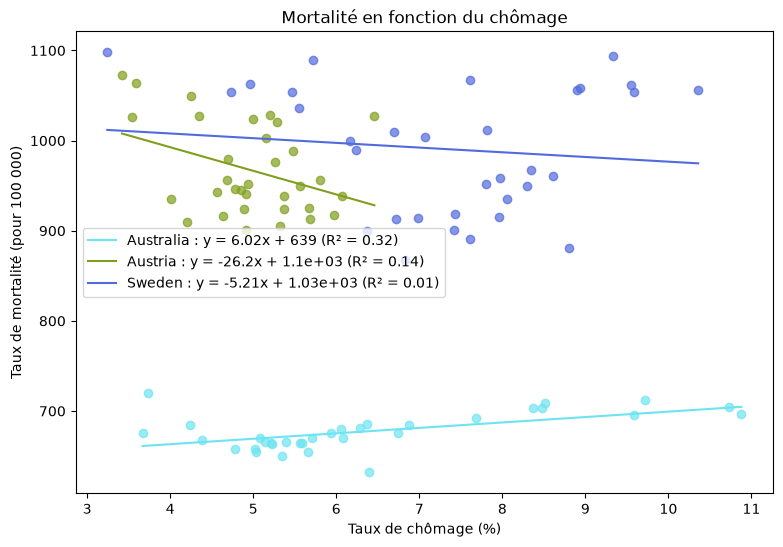

In [ ]:
import importlib
import modules.Econometrics.Debut_etudes   
importlib.reload(modules.Econometrics.Debut_etudes)
from modules.Econometrics.Debut_etudes import *

plot_mortalite_chomage_pays(df_final, ["Australia", "Austria", "Sweden"])

##### <u> 2. Par année <u>

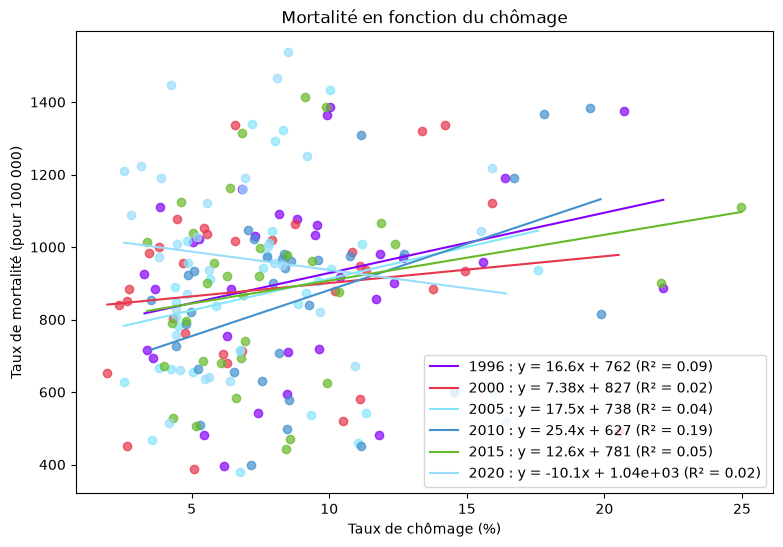

In [37]:
plot_mortalite_chomage_annee(df_final, [1996, 2000, 2005,2010, 2015, 2020])

/home/onyxia/work/Projet-Python/modules/Econometrics/Debut_etudes.py:96: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


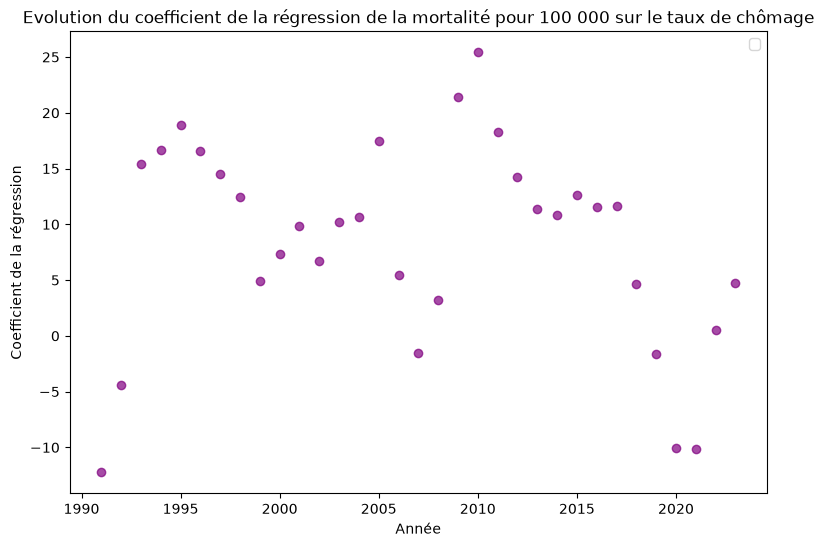

In [38]:
plot_coeff_reg_mortalite_chomage(df_final)

### **<u> III. Etude de l'impact du chômage sur la mortalité, causes par causes <u>**

Etude des corrélations

*Ici taux de chômage et mortalité et variation taux de chômage (en points) et variation mortalité, pour chaque cause*

In [ ]:
from modules.Econometrics.Correlations import *

resultat = correlation_par_cause(df_final, "Taux_chômage", "value")
resultat

,corr_niveaux,corr_variation
cause_name,,
All causes,0.14,0.07
Homicide,0.19,0.02
"Liver diseases, cirrhosis",0.03,-0.10
Major cardiovascular diseases,0.19,-0.04
Malignant neoplasm,-0.05,-0.00
Motor vehicle accidents,0.27,-0.28
Other accidents,0.10,-0.10
Pneumonia and influenza,-0.10,-0.04
Suicide,0.09,0.24


On calcule, pour chaque cause de décès, la corrélation entre le taux de chômage et le taux de mortalité, en niveaux puis en variations annuelles. En niveaux, les corrélations peuvent être trompeuses (tendances communes, différences entre pays) : par exemple, elles changent de signe pour les accidents de la route.
Deux causes de décès ressortent : le suicide (0,24), qui augmente lorsque le chômage augmente, et les accidents de la route (-0,28), qui baissent quand le chômage augmente. 

Régression

In [ ]:
for c in df_final["cause_name"].dropna().unique():
    print(c, regression(df_final, c))


All causes (np.float64(0.0020588269056317633), np.float64(0.5009029853380619))
Malignant neoplasm (np.float64(0.0004564577831080252), np.float64(0.8667676354453522))
Major cardiovascular diseases (np.float64(0.0006854167121786343), np.float64(0.8679959108525355))
Liver diseases, cirrhosis (np.float64(-0.008780402146845397), np.float64(0.1106866883627179))
Pneumonia and influenza (np.float64(0.0045546441966468985), np.float64(0.7222854497612472))
Motor vehicle accidents (np.float64(-0.0014856352488498061), np.float64(0.8026940781070516))
Suicide (np.float64(0.015155043391181443), np.float64(0.0019881155190705634))
Other accidents (np.float64(0.003681776569506064), np.float64(0.4934227942429954))
Homicide (np.float64(0.01600742104787678), np.float64(0.02433640753823231))


Suicide : une augmentation de 1 point de pourcentage du chômage est associée à une hausse moyenne d'environ 1,5 % de la mortalité par suicide. L'effet est statistiquement très robuste (p-value<0.01).

Accidents de la route : Le signe est négatif (ce qui rejoint l'intuition d'une baisse de déplacements automobiles lorsque le chômage augmente), mais la p-value de 0,80 ce qui ne permet pas de conclure quant à la significativité.